In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

In [5]:
from pathlib import Path

BASE_DIR = Path(r"D:\RetailMind")

MODEL_PATH = BASE_DIR / "models" / "best_product_cnn.keras"

DATA_DIR = BASE_DIR / "data" / "raw"

classifier = tf.keras.models.load_model(MODEL_PATH)

print("CNN model loaded successfully!")
print("Model input shape:", classifier.input_shape)
print("Model output shape:", classifier.output_shape)

CNN model loaded successfully!
Model input shape: (None, 128, 128, 3)
Model output shape: (None, 5)


In [15]:
CSV_PATH = BASE_DIR / "data" / "products" / "styles.csv"

df = pd.read_csv(CSV_PATH, on_bad_lines="skip")

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

df.head()

Dataset shape: (44424, 10)

Available columns:
['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [18]:
category_counts = df["articleType"].value_counts()

selected_categories = category_counts[
    (category_counts >= 50) & (category_counts <= 200)
]

print(selected_categories)

articleType
Nightdress               189
Leggings                 177
Pendant                  176
Capris                   175
Necklace and Chains      160
Lip Gloss                144
Night suits              141
Trunk                    140
Skirts                   128
Scarves                  119
Ring                     118
Dupatta                  116
Cufflinks                106
Kajal and Eyeliner       102
Accessory Gift Set        97
Kurta Sets                94
Free Gifts                91
Stoles                    90
Duffel Bag                88
Bangle                    85
Laptop Bag                82
Foundation and Primer     76
Sports Sandals            67
Bracelet                  66
Lounge Pants              61
Face Moisturisers         61
Jewellery Set             58
Fragrance Gift Set        57
Highlighter and Blush     53
Boxers                    52
Name: count, dtype: int64


In [19]:
TARGET_CATEGORY = "Leggings"

category_df = df[df["articleType"] == TARGET_CATEGORY]

print("Category:", TARGET_CATEGORY)
print("Number of images:", len(category_df))

Category: Leggings
Number of images: 177


In [20]:
category_df = category_df.copy()

category_df["image_path"] = category_df["id"].apply(
    lambda x: IMAGE_DIR / f"{x}.jpg"
)

category_df = category_df[
    category_df["image_path"].apply(lambda x: x.exists())
]

print("Available images:", len(category_df))
print(category_df[["id", "articleType", "image_path"]].head())

Available images: 177
         id articleType                                    image_path
631   12163    Leggings  D:\RetailMind\data\products\images\12163.jpg
967   23044    Leggings  D:\RetailMind\data\products\images\23044.jpg
1014  12155    Leggings  D:\RetailMind\data\products\images\12155.jpg
1240  23043    Leggings  D:\RetailMind\data\products\images\23043.jpg
1689  39122    Leggings  D:\RetailMind\data\products\images\39122.jpg


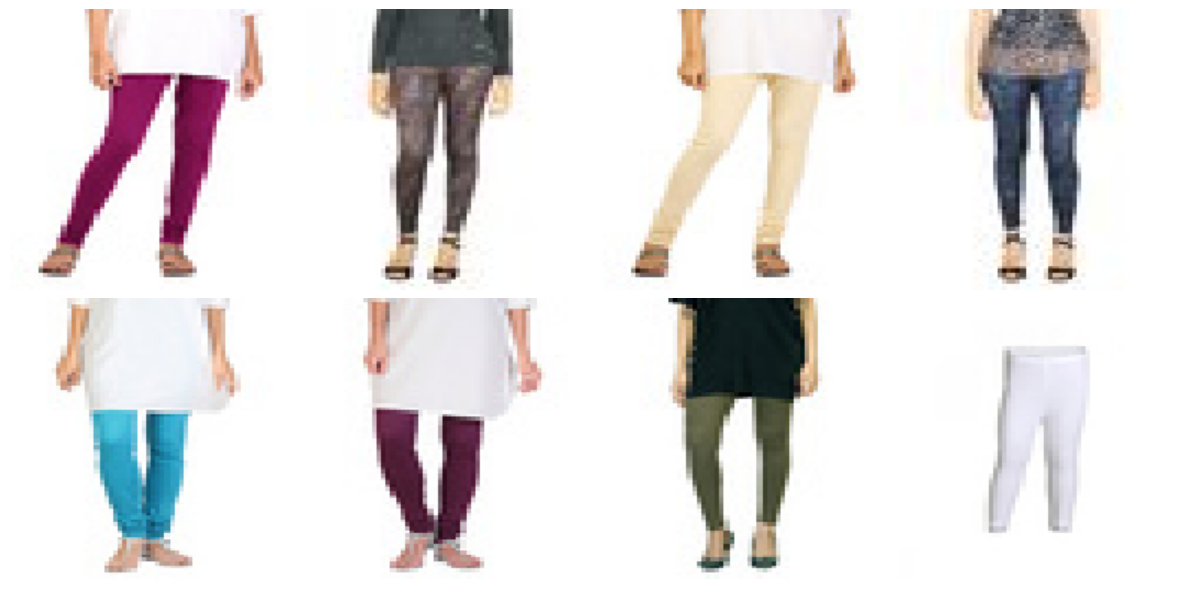

In [21]:
plt.figure(figsize=(12, 6))

for i in range(8):
    img = tf.keras.utils.load_img(
        category_df.iloc[i]["image_path"],
        target_size=(128, 128)
    )

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
images = []

for path in category_df["image_path"]:
    img = tf.keras.utils.load_img(
        path,
        target_size=(128, 128)
    )

    img = tf.keras.utils.img_to_array(img)
    img = img / 255.0

    images.append(img)

images = np.array(images, dtype="float32")

print("Image dataset shape:", images.shape)
print("Minimum pixel value:", images.min())
print("Maximum pixel value:", images.max())

Image dataset shape: (177, 128, 128, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [23]:
from sklearn.model_selection import train_test_split

train_images, val_images = train_test_split(
    images,
    test_size=0.2,
    random_state=42
)

print("Training images:", train_images.shape)
print("Validation images:", val_images.shape)

Training images: (141, 128, 128, 3)
Validation images: (36, 128, 128, 3)


In [24]:
latent_dim = 128

encoder_inputs = tf.keras.Input(shape=(128, 128, 3))

x = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(encoder_inputs)
x = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2D(128, 3, strides=2, padding="same", activation="relu")(x)

x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(256, activation="relu")(x)

z_mean = tf.keras.layers.Dense(latent_dim, name="z_mean")(x)
z_log_var = tf.keras.layers.Dense(latent_dim, name="z_log_var")(x)

encoder = tf.keras.Model(
    encoder_inputs,
    [z_mean, z_log_var],
    name="encoder"
)

encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 32, 32,    │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 16, 16,    │     73,856 │ conv2d_1[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 32768)     │          0 │ conv2d_2[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  8,388,864 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 128)       │     32,896 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,547,904 (32.61 MB)

 Trainable params: 8,547,904 (32.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:
latent_inputs = tf.keras.Input(shape=(latent_dim,))

x = tf.keras.layers.Dense(16 * 16 * 128, activation="relu")(latent_inputs)
x = tf.keras.layers.Reshape((16, 16, 128))(x)

x = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
x = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)

decoder_outputs = tf.keras.layers.Conv2D(
    3, 3, padding="same", activation="sigmoid"
)(x)

decoder = tf.keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)

decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32768)          │     4,227,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 128)    │       147,584 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 64, 64, 64)     │        73,792 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 128, 128, 32)   │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,467,779 (17.04 MB)

 Trainable params: 4,467,779 (17.04 MB)

 Non-trainable params: 0 (0.00 B)

In [26]:
class Sampling(tf.keras.layers.Layer):

    def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(shape=tf.shape(z_mean))

        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


sampling = Sampling()

z = sampling([z_mean, z_log_var])

print("Latent vector shape:", z.shape)


Latent vector shape: (None, 128)


In [27]:
vae_inputs = tf.keras.Input(shape=(128, 128, 3))

z_mean, z_log_var = encoder(vae_inputs)

z = Sampling()([z_mean, z_log_var])

vae_outputs = decoder(z)

vae = tf.keras.Model(
    vae_inputs,
    vae_outputs,
    name="VAE"
)

print("VAE created successfully!")
print("Input shape:", vae.input_shape)
print("Output shape:", vae.output_shape)

VAE created successfully!
Input shape: (None, 128, 128, 3)
Output shape: (None, 128, 128, 3)


In [39]:
class VAE(tf.keras.Model):

    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs):
        z_mean, z_log_var = self.encoder(inputs)
        z = Sampling()([z_mean, z_log_var])
        return self.decoder(z)

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var = self.encoder(data)
            z = Sampling()([z_mean, z_log_var])
            reconstruction = self.decoder(z)

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.losses.binary_crossentropy(
                        data, reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1 + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = reconstruction_loss + kl_loss

        gradients = tape.gradient(
            total_loss, self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(gradients, self.trainable_weights)
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }
    def test_step(self, data):

    if isinstance(data, tuple):
        data = data[0]

    z_mean, z_log_var = self.encoder(data)
    z = Sampling()([z_mean, z_log_var])
    reconstruction = self.decoder(z)

    reconstruction_loss = tf.reduce_mean(
        tf.reduce_sum(
            tf.keras.losses.binary_crossentropy(data, reconstruction),
            axis=(1, 2)
        )
    )

    kl_loss = -0.5 * tf.reduce_mean(
        tf.reduce_sum(
            1 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var),
            axis=1
        )
    )

    return {"loss": reconstruction_loss + kl_loss}

IndentationError: expected an indented block after function definition on line 57 (2513284896.py, line 59)

In [37]:
vae.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=lambda y_true, y_pred: tf.constant(0.0)
)

In [43]:
history = vae.fit(
    train_images,
    epochs=30,
    batch_size=16,
    validation_data=None
)

Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 350ms/step - kl_loss: 174.0982 - loss: 5370.4082 - reconstruction_loss: 5196.3101
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 264ms/step - kl_loss: 128.4261 - loss: 5166.5415 - reconstruction_loss: 5038.1152
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 297ms/step - kl_loss: 104.6710 - loss: 5077.0146 - reconstruction_loss: 4972.3438
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 274ms/step - kl_loss: 76.9700 - loss: 5003.0566 - reconstruction_loss: 4926.0869
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 246ms/step - kl_loss: 81.8026 - loss: 4996.0498 - reconstruction_loss: 4914.2471
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 254ms/step - kl_loss: 70.0061 - loss: 4911.7139 - reconstruction_loss: 4841.7080
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 241ms/step - kl_loss: 59.4690 - loss: 4970.7344 - reconstruction_loss: 4911.2656
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 260ms/step - kl_loss: 58.2983 - loss: 4847.5830 - reconstruction_loss: 4789.2847
Epoch 9/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 2

In [44]:
# Generate random latent vectors
random_latent = tf.random.normal(shape=(8, latent_dim))

# Generate images
generated_images = decoder.predict(random_latent)

print("Generated images shape:", generated_images.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 544ms/step
Generated images shape: (8, 128, 128, 3)


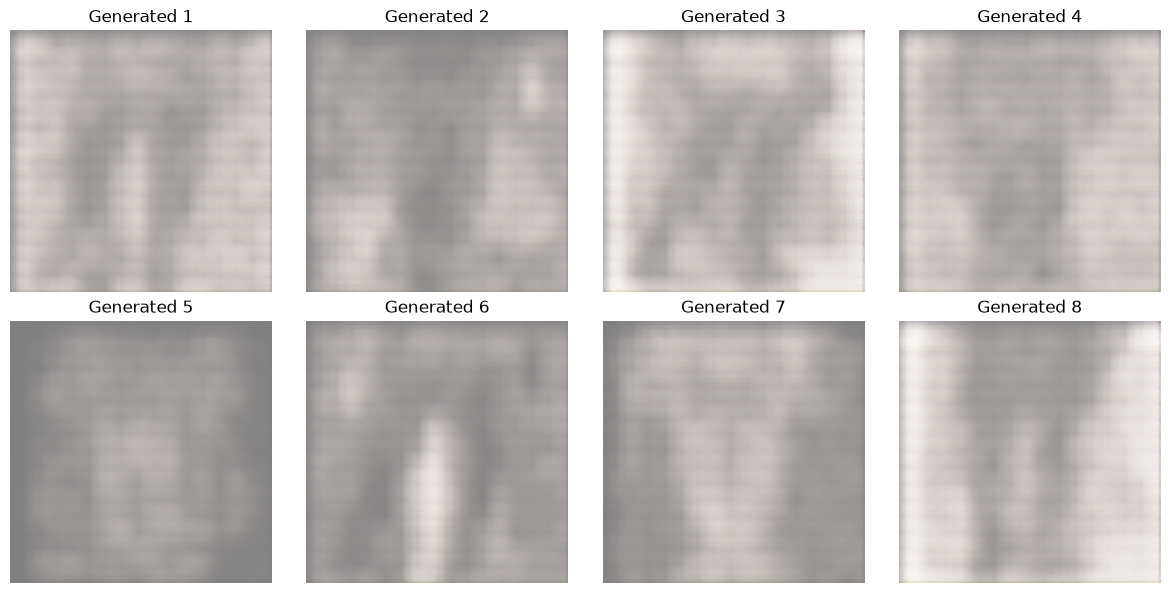

In [45]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")
    plt.title(f"Generated {i+1}")

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step


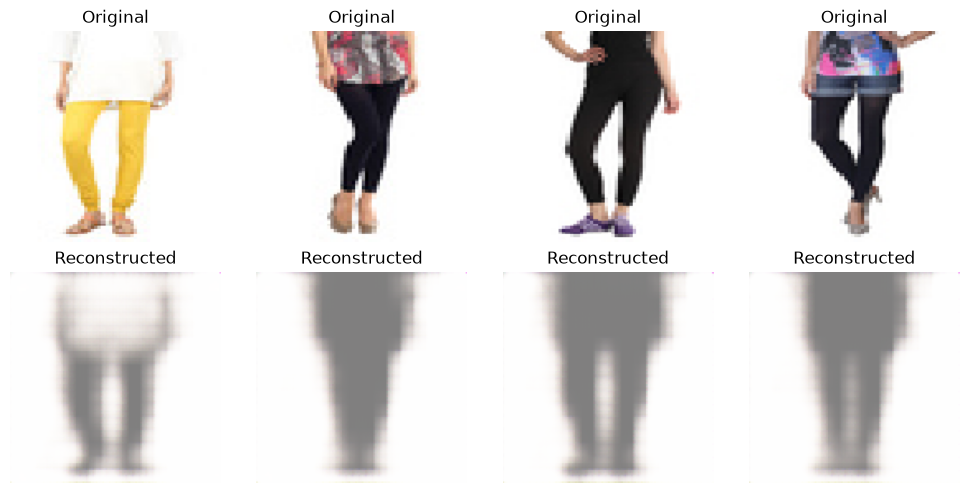

In [46]:
z_mean, z_log_var = encoder.predict(train_images[:4])

reconstructed = decoder.predict(z_mean)

plt.figure(figsize=(10, 5))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(train_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(reconstructed[i])
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [47]:
history = vae.fit(
    train_images,
    initial_epoch=30,
    epochs=100,
    batch_size=16
)

Epoch 31/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 351ms/step - kl_loss: 67.9851 - loss: 4152.5811 - reconstruction_loss: 4084.5959
Epoch 32/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 294ms/step - kl_loss: 75.9436 - loss: 4104.8628 - reconstruction_loss: 4028.9189
Epoch 33/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 284ms/step - kl_loss: 79.2875 - loss: 4111.6187 - reconstruction_loss: 4032.3311
Epoch 34/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 285ms/step - kl_loss: 79.6234 - loss: 4107.1328 - reconstruction_loss: 4027.5095
Epoch 35/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - kl_loss: 76.9264 - loss: 4064.3142 - reconstruction_loss: 3987.3879
Epoch 36/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 256ms/step - kl_loss: 76.6923 - loss: 4037.8408 - reconstruction_loss: 3961.1484
Epoch 37/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 254ms/step - kl_loss: 84.1984 - loss: 4032.8218 - reconstruction_loss: 3948.6233
Epoch 38/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 262ms/step - kl_loss: 78.1753 - loss: 4004.9509 - reconstruction_loss: 3926.7756
Epoch 39/100
9/9 ━━━━━━━

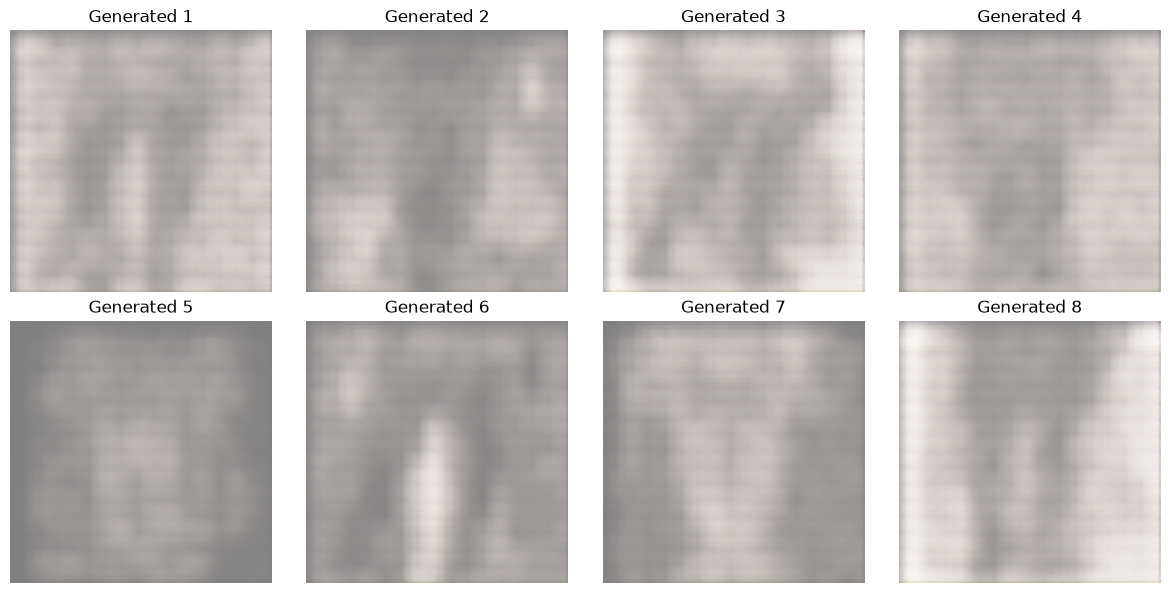

In [48]:
plt.figure(figsize=(12, 6))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(generated_images[i])
    plt.axis("off")
    plt.title(f"Generated {i+1}")

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step


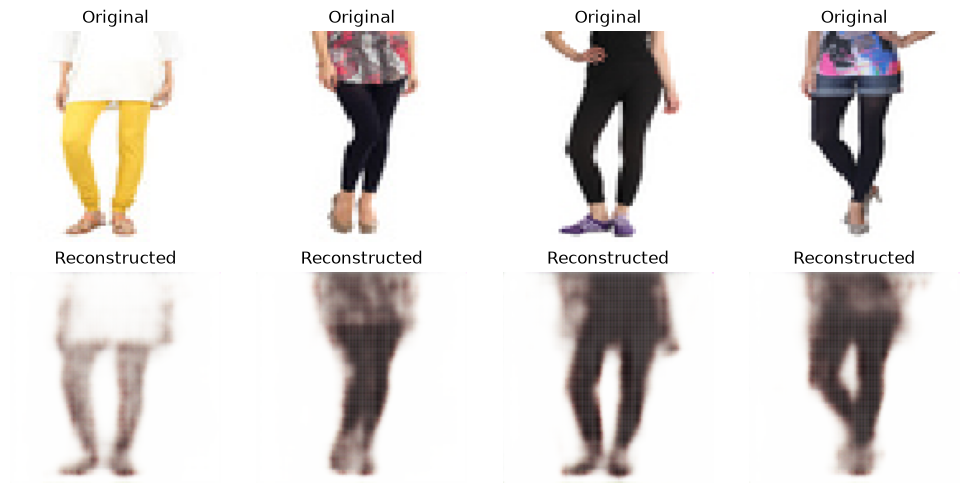

In [49]:
z_mean, z_log_var = encoder.predict(train_images[:4])

reconstructed = decoder.predict(z_mean)

plt.figure(figsize=(10, 5))

for i in range(4):
    plt.subplot(2, 4, i + 1)
    plt.imshow(train_images[i])
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, 4, i + 5)
    plt.imshow(reconstructed[i])
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [51]:
MODEL_DIR = BASE_DIR / "models"

vae.save_weights(MODEL_DIR / "leggings_vae.weights.h5")

encoder.save(MODEL_DIR / "leggings_encoder.keras")

decoder.save(MODEL_DIR / "leggings_decoder.keras")

print("VAE weights, encoder and decoder saved successfully!")

VAE weights, encoder and decoder saved successfully!
